## Delivery Time Estimation with Linear Regression

# 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv(r'D:\Machine Learning Models\taco_sales.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(1000, 13)


,Order ID,Restaurant Name,Location,Order Time,Delivery Time,Delivery Duration (min),Taco Size,Taco Type,Toppings Count,Distance (km),Price ($),Tip ($),Weekend Order
0,770487,El Taco Loco,New York,01-08-2024 14:55,01-08-2024 15:36,41,Regular,Chicken Taco,5,3.01,9.25,2.22,False
1,671858,El Taco Loco,San Antonio,23-11-2024 17:11,23-11-2024 17:25,14,Regular,Beef Taco,1,6.20,4.25,3.01,True
2,688508,Taco Haven,Austin,21-11-2024 20:24,21-11-2024 21:02,38,Large,Pork Taco,2,20.33,7.00,0.02,False
3,944962,Spicy Taco House,Dallas,21-09-2024 06:43,21-09-2024 07:28,45,Regular,Chicken Taco,2,3.00,5.50,1.90,True
4,476417,Casa del Taco,San Antonio,24-07-2024 11:01,24-07-2024 11:16,15,Large,Pork Taco,0,24.34,4.50,1.14,False


## 2. Data Quality Checks


- Parse the timestamps  (day-first format) and verify that Delivery Duration (min) equals Delivery Time - Order Time - it does so the target is internally consistent.
- No Missing values; 1000 orders; durations range 10-90 min.

In [3]:
df['Order Time'] = pd.to_datetime(df['Order Time'], format='%d-%m-%Y %H:%M')
df['Delivery Time'] = pd.to_datetime(df['Delivery Time'], format='%d-%m-%Y %H:%M')

calc = (df['Delivery Time'] - df['Order Time']).dt.total_seconds() / 60
print('duration columns matches matches timestamps:', np.allclose(calc, df['Delivery Duration (min)']))
print('missing values:', df.isna().sum().sum())
df.describe().T


duration columns matches matches timestamps: True
missing values: 0


,count,mean,min,25%,50%,75%,max,std
Order ID,1000.0,552504.865,101139.0,331796.75,559740.0,771781.75,999138.0,255948.779709
Order Time,1000,2024-09-16 15:44:16.080000,2024-01-01 18:39:00,2024-05-13 08:09:15,2024-09-17 23:32:30,2025-01-23 05:48:15,2025-05-24 14:57:00,NaN
Delivery Time,1000,2024-09-16 16:35:11.880000,2024-01-01 19:48:00,2024-05-13 09:27:00,2024-09-18 00:20:00,2025-01-23 07:01:15,2025-05-24 15:45:00,NaN
Delivery Duration (min),1000.0,50.93,10.0,30.0,53.0,71.0,90.0,23.22754
Toppings Count,1000.0,2.529,0.0,1.0,3.0,4.0,5.0,1.717005
Distance (km),1000.0,13.07342,0.51,6.9725,13.2,19.2425,24.98,7.142268
Price ($),1000.0,6.90825,3.0,4.5,6.75,9.25,10.75,2.310137
Tip ($),1000.0,1.80611,0.01,0.9075,1.76,2.52,4.98,1.132035


# 3. Exploratory Data Analysis

Key questions: does delivery time grow with distance? With toppings? With order hour?

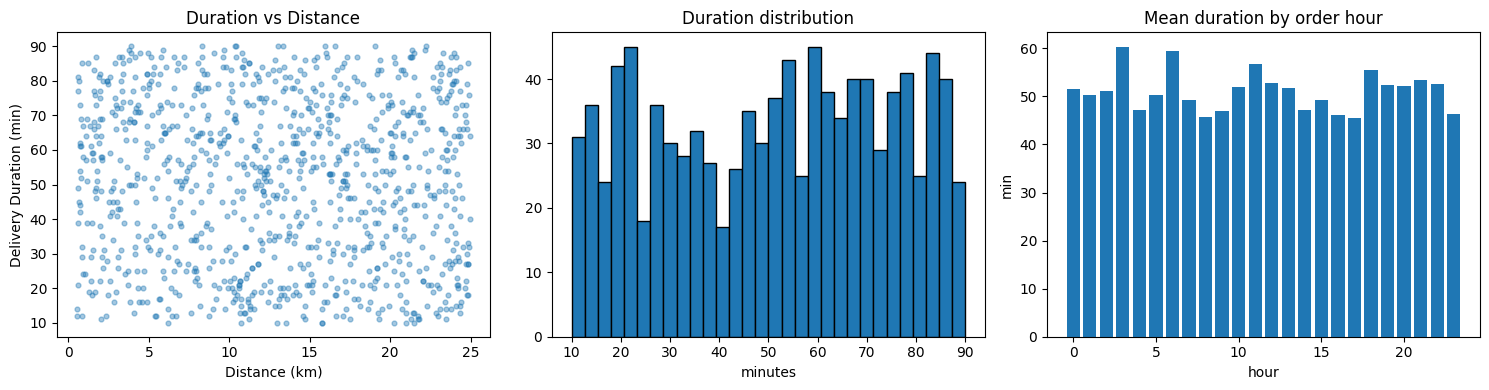

corr(duration, Distance (km)) = -0.056
corr(duration, Toppings Count) = -0.029
corr(duration, Price ($)) = -0.035
corr(duration, Tip ($)) = -0.018


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(df['Distance (km)'], df['Delivery Duration (min)'], alpha=0.4, s=12)
axes[0].set(xlabel='Distance (km)', ylabel='Delivery Duration (min)', title='Duration vs Distance')

axes[1].hist(df['Delivery Duration (min)'], bins=30, edgecolor='k')
axes[1].set(title='Duration distribution', xlabel='minutes')

by_h = df.groupby(df['Order Time'].dt.hour)['Delivery Duration (min)'].mean()
axes[2].bar(by_h.index, by_h.values)
axes[2].set(title='Mean duration by order hour', xlabel='hour', ylabel='min')

plt.tight_layout(); plt.show()

for c in ['Distance (km)', 'Toppings Count', 'Price ($)', 'Tip ($)']:
    print(f"corr(duration, {c}) = {df[c].corr(df['Delivery Duration (min)']):+.3f}")

EDA outcome: Each correlation with the target is = 0 (distance: - 0.056). The Scatter plot shows a shapeless cloud, and the duration distribution is close to uniform over 10-90 min. This strongly suggests the data is synthetic/random 

## Feature Engeneering

From the timestamps we extract hour, dayofweek, month; categoricals (Restaurant Name, Location, Taco Size, Taco Type) are one-hot encoded; Weekend Order is cast to int.

In [5]:
# Temporal features
df['hour'] = df['Order Time'].dt.hour
df['dayofweek'] = df['Order Time'].dt.dayofweek
df['month'] = df['Order Time'].dt.month

# Our Target
y = df['Delivery Duration (min)']

In [6]:
# Numeric Features
num_cols = [
    'Distance (km)',
    'Toppings Count',
    'Weekend Order',
    'hour',
    'dayofweek',
    'month',
]

X_num = df[num_cols].copy()
X_num["Weekend Order"] = X_num["Weekend Order"].astype(int)

cat_cols = {
    "Restaurant Name": "rest",
    "Location": "loc",
    "Taco Size": "size",
    "Taco Type": "type",
}

X_cat = pd.concat(
    [
        pd.get_dummies(df[col], prefix=prefix, drop_first=True) for col, prefix in cat_cols.items()
    ],
    axis=1,
)

# combine numeric and categorical features
X_full = pd.concat([X_num, X_cat], axis=1).astype(np.float32)
print("feature matrix:", X_full.shape)

feature matrix: (1000, 29)


## 5. Model Training & Evaluation


In [7]:
def evaluate(X, name, y=y, model=None, test_size=0.2, random_state=42):

    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    m = model if model is not None else LinearRegression()
    m.fit(Xtr, ytr)
    pred = m.predict(Xte)

    mae = mean_absolute_error(yte, pred)
    rmse = mean_squared_error(yte, pred) ** 0.5
    r2 = r2_score(yte, pred)

    print(f"{name:38s} MAE={mae:6.2f} RMSE={rmse:6.2f} R2={r2:+.3f}")
    return m, yte, pred

# Feature
X_dist = df[["Distance (km)"]]    

X_num = df[["Distance (km)", "Toppings Count", "Price ($)", "Tip ($)"]].copy()
X_num["Weekend Order"] = df["Weekend Order"].astype(int)

# compare models
m1, yte1, pred1 = evaluate(X_dist, "LinearReg: distance only")
m2, yte2, pred2 = evaluate(X_num, "LinearReg: numeric features")
m3, yte3, pred3 = evaluate(X_full, "LinearReg: full features")
evaluate(X_full, "Ridge: full features", model=Ridge(alpha=1.0))
evaluate(X_full, "Dummy (predict mean)", model=DummyRegressor(strategy="mean"))

LinearReg: distance only               MAE= 19.39 RMSE= 22.44 R2=-0.002
LinearReg: numeric features            MAE= 19.36 RMSE= 22.43 R2=-0.000
LinearReg: full features               MAE= 19.60 RMSE= 22.77 R2=-0.031
Ridge: full features                   MAE= 19.58 RMSE= 22.74 R2=-0.029
Dummy (predict mean)                   MAE= 19.45 RMSE= 22.51 R2=-0.008


(DummyRegressor(),
 521    12
 737    16
 740    72
 660    86
 411    31
        ..
 408    23
 332    25
 208    74
 613    87
 78     26
 Name: Delivery Duration (min), Length: 200, dtype: int64,
 array([51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32375, 51.32375,
        51.32375, 51.32375, 51.32375, 51.32375, 51.32

## Diagnostics

Three plots tell the story:
1. Predicted vs actual (distance-only model): predictions collapse onto a flat line - the model output is essentially the mean regardless of input.
2. Residuals (full model): no structure, but huge spread (+-40 min) - the model explains none of the variance
3. Coefficients: all near zero; the fitted distance effect is -0.16 min/km (= -10 sec per km) - physically nonsensical, confirming noise-fitting.

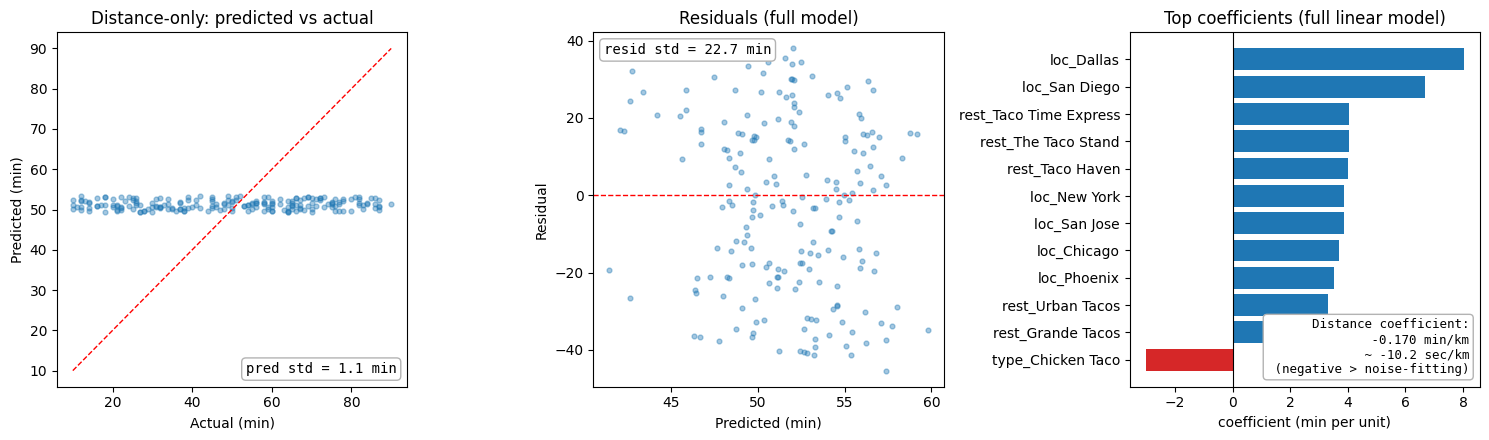

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Distance-only: predicted vs actual
ax = axes[0]
ax.scatter(yte1, pred1, alpha=0.4, s=12)
lims = [min(yte1.min(), pred1.min()), max(yte1.max(), pred1.max())]
ax.plot(lims, lims, "r--", lw=1)
ax.set(xlabel="Actual (min)", ylabel="Predicted (min)", title="Distance-only: predicted vs actual")
ax.text(0.97, 0.03, f"pred std = {pred1.std():.1f} min", 
        transform=ax.transAxes, ha="right", va="bottom", fontsize=10, family="monospace",
        bbox=dict(boxstyle="round", fc="white", ec="0.7"),
)

# Full model: residuals
resid = yte3 - pred3
ax = axes[1]
ax.scatter(pred3, resid, alpha=0.4, s=12)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set(xlabel="Predicted (min)", ylabel="Residual", title="Residuals (full model)")
ax.text(0.03, 0.97, f"resid std = {resid.std():.1f} min",
        transform=ax.transAxes, ha="left", va="top",
        fontsize=10, family="monospace",
        bbox=dict(boxstyle="round", fc="white", ec="0.7"),
        )

# Full model: top- /coef/ features
coefs = (
    pd.Series(m3.coef_, index=X_full.columns)
    .sort_values(key=abs, ascending=False)
    .head(12)
)        
ax = axes[2]
ax.barh(coefs.index[::-1], coefs.values[::-1],
        color=["tab:red" if c < 0 else "tab:blue" for c in coefs.values[::-1]])
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Top coefficients (full linear model)",
       xlabel="coefficient (min per unit)")
ax.text(
    0.97, 0.03, 
    f"Distance coefficient:\n"
    f" {m3.coef_[X_full.columns.get_loc('Distance (km)')]:+.3f} min/km\n"
    f" ~ {m3.coef_[X_full.columns.get_loc('Distance (km)')] * 60:+.1f} sec/km\n"
    f" (negative > noise-fitting)",
    transform=ax.transAxes, ha="right", va="bottom",
    fontsize=9, family="monospace",
    bbox=dict(boxstyle="round", fc="white", ec="0.7"),
)       

plt.tight_layout()
plt.show()


# 7. Conclusions
clean data, verified target, proper train/test split, baseline comparison, residual diagnostics.
I have realized that my data is the problem: delivery duration is statistically independent of every available feature (R2 ~ on held-out data; negative with more features = overfitting noise)

### Next step
Validate the data source
Collect real predictive features
Then climb the model ladder
Keep the dummy baseline
